# 109 · Paper tables and figures

One trained run → every table and figure for the paper. Set `RUN` (env var `RUN` overrides). All of the logic is in `src8/paper.py`: `load` builds one row per sample, and each table or plot is one function that takes that DataFrame.

- **Section 0, the data** (no model): coverage of the floor, average spectra (per speaker, box, object, laser row / column, position row / column), how stable the empty box is over a session, spectral distance over the floor and vs distance moved, damping (envelope, time to noise), spatial patterns (how many, their shapes), what an object changes in the modes (frequency, shape, amplitude), whether the four objects change the box differently, and the box's own resonances.

- **Table 1, in distribution** (one table per metric): rows = method × box. Columns = train and eval (the mean of the 6 in-distribution splits) ‖ eval per split (candle, cube, soap dispenser, vase, two cubes, cube + vase). kNN baseline (on the inputs) vs VibroFormer.
- **Every table is also a bar plot:** x = its columns, one bar per box, the value and ±std written on each bar with a ±1 std whisker, and `tr` / `te` (train / test samples) under each bar.
- **Table 2, out of distribution** (one table per metric): only conditions the model never trained on at all, × box. That is unseen speaker, object, rotation, speckles (shifted lasers), lid on, and the broken cup; in distribution is the reference row. Unseen position comes with a `--dataset paper` run.
- **Weight trend:** the cylinders (one shape, four masses) are all trained, so weight is a trend of performance vs mass, not a generalization test.
- **Table 3, aux heads**, and the train/test sample counts behind Tables 1 and 2.
- **Figures:** floor error map, IoU vs distance to the nearest training position, per speaker, object-head confidence, and predicted samples per category.

**Cells** show *mean ±std*. The mean is over splits (every split counts once); the std is over samples. Colour shades each cell from worst (white) to best (blue) down each column (Table 1) or along each row (Table 2, i.e. which box). The best is in bold, and "all" is not compared. Thick rules separate the row labels, train/eval from the per-split breakdown, and the methods. `to_latex` writes the same table for the paper (`\usepackage[table]{xcolor}`, `booktabs`, `multirow`, `array`).

**Metrics** (`THR` = 0.1): IoU = hard IoU of pred > THR vs true > 0.5. miss = no predicted pixel on the object. CoM err = distance between the predicted and true mask centroids, in % of the box.

**Which rows a run fills:** each eval split maps to its question (`dataset.PAPER_CATEGORY`). An object question (unseen object, object + rotation, weight, broken) only counts if the run never trained on that object. A run on an older dataset therefore fills only what it really held out. Unseen position, the cardboard wedge, unseen weight and broken need a run trained with `--dataset paper`.

In [1]:
import os, sys
from pathlib import Path
import pandas as pd
sys.path.insert(0, str(Path('..') / 'src8'))
import paper as P

RUN = os.environ.get('RUN', 's8-mag-nopose-imom-r2-500ep')
EPOCH = None          # None: the run's last saved eval
THR = 0.1
OUT = Path('..') / 'runs' / RUN / 'paper_tables'   # LaTeX tables land here
OUT.mkdir(exist_ok=True)

/home/ethantu/workspace/good-vibrations/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1061: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


## 0 The data
Before any model: what was recorded, how stable it is, and what moving an object does to the box's vibration. Everything is built from the run's own dataset (`RUN` above): its splits, its train / eval positions, its speakers. The logic is in `src8/paper.py` section 5.

**Setup**
- Three boxes (gastro = steel gastronorm tray, plastic, cardboard). Each has a 10×10 grid of laser spots on the bottom wall and an overhead camera. A speaker plays a log chirp (100 → 1000 Hz, 1 s), and the camera tracks every laser spot's speckle shift at 2500 fps for 1.3 s.
- One **capture** = one object layout at one position, played by one speaker. Each position is recorded once per speaker (1/3/5/7; gastro has no 5).
- **Objects**: the four single-object in-distribution splits: candle, cube, soap dispenser, vase. `objects=None` means all four, or pass one split name. The empty-box captures (layouts `empty-box-*`) are spread over each session.

**Definitions** (as in nb99)
- `X(l, f, c)`: complex FFT of the shift of laser `l` (100), axis `c` (x, y), at `f` ∈ 100–1000 Hz (1170 bins of 0.77 Hz; whole-capture Hann window).
- `x(l, j, c) = mean_{f ∈ band j} 20 log10 |X|`: dB in 117 bands of 10 bins (7.7 Hz).
- **Spectral distance**: `D_spec(a, b) = sqrt(mean_{l,j,c} (x_a − x_b)²)`, in dB.
- **Level**: `L(f) = 10 log10 mean_{l,c} |X|²`.
- **Repeat noise**: `D_spec` of two back-to-back captures of the empty box (same layout and speaker). Nothing moved, so this is the floor every change is read against.
- **Position distance**: `D_pos(a, b) = |com_a − com_b| / sqrt(H·W)`: how far the object moved, as a fraction of the box (CoM in the overhead crop).

**Averaging rule** (every function): spectra are only compared within one *(object, speaker)* group. Each group is computed on its own; curves are the **mean over groups**, and bands are **± the pooled within-group std** (`sqrt(mean variance)`), so the difference between speakers or objects never widens a band. `speakers=None` means every speaker; pass one to see it alone. Each box has one colour. The two caveats: a mean over objects can hide one object that behaves differently (pass `objects=` to check), and where a band is a std *between* groups instead, the plot says so.

Slow parts (FFTs, envelopes, SVDs) are cached in `runs/_paper_cache/data/` and `runs/<run>/scores/`. The first run of the section takes ~5 min; after that it takes seconds.

In [2]:
cap = P.captures(RUN)
cap[cap.split.isin(P.OBJECTS + ('empty-box',))].groupby(['box', 'split']).agg(captures=('dir', 'size'), positions=('position_id', 'nunique'),
    train_pos=('set', lambda s: (s == 'train').sum()), eval_pos=('set', lambda s: (s == 'eval').sum()), speakers=('speaker', lambda s: sorted(set(s)))).unstack(0)

captures                positions                train_pos  \
box            cardboard gastro plastic cardboard gastro plastic cardboard   
split                                                                        
candle              1156    780    1012       289    260     253       924   
cube                1116    738    1008       279    246     252       892   
empty-box             76     36      60        19     12      15        76   
soap-dispenser      1088    735    1182       272    245     296       872   
vase                1028    804    1024       257    268     256       824   

                               eval_pos                     speakers  \
box            gastro plastic cardboard gastro plastic     cardboard   
split                                                                  
candle            624     808       232    156     204  [1, 3, 5, 7]   
cube              591     808       224    147     200  [1, 3, 5, 7]   
empty-box          36      60         0      0       0  [1, 3, 5, 7]   
soap-dispenser    588     948       216    147     234  [1, 3, 5, 7]   
vase              642     820       204    162     204  [1, 3, 5, 7]   

                                         
box                gastro       plastic  
split                                    
candle          [1, 3, 7]  [1, 3, 5, 7]  
cube            [1, 3, 7]  [1, 3, 5, 7]  
empty-box       [1, 3, 7]  [1, 3, 5, 7]  
soap-dispenser  [1, 3, 7]  [1, 3, 5, 7]  
vase            [1, 3, 7]  [1, 3, 5, 7]

### 0.1 Coverage: where the objects were put
Every position's true outline (`03_smask` > 0.5) and centre of mass, drawn on the box's whole first empty-box overhead photo (`02_cropped_overhead`, not cropped further). Train positions are in the box's colour, eval positions in black. A position counts once, because its mask is the same for every speaker. `P.plot_coverage(RUN, objects, box, speakers)` draws any object / box / speaker; the default object is the cube.

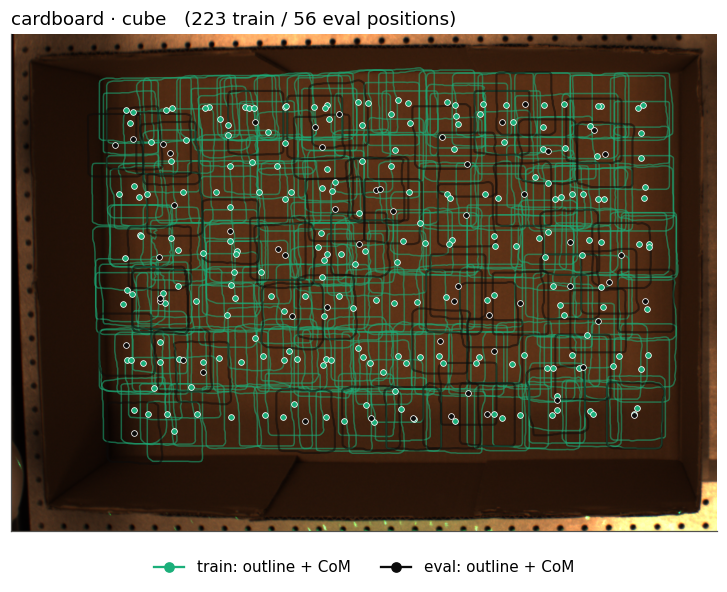

In [3]:
P.plot_coverage(RUN, box='cardboard');

**Reading:**
- The cardboard cube covers the whole floor evenly (223 train / 56 eval positions), up to about one cube width from the walls.
- Its footprint is about a tenth of the floor's width, so neighbouring outlines overlap: the grid is denser than the cube is wide.
- The eval positions are spread among the train positions, not in a separate region: random held-out positions test interpolation. Only the `unseen-position` block of a `--dataset paper` run tests new territory.

### 0.2 Average spectra
Power `P(f)` = mean over the 100 lasers and both axes of `10 log10 |X(l, f, c)|²` (dB), in 7.7 Hz bands: one curve per capture. Line = mean over captures, band = ± std over captures. `P.plot_avg_fft(RUN, by, box, objects, speakers)` draws one line per value of `by`:
- `'speaker'`, `'box'`, `'object'`;
- `'laser_row'` / `'laser_col'`: the lasers of one row or column of the 10 × 10 grid on the wall (laser `l` at row `l // 10`, column `l % 10`);
- `'pos_row'` / `'pos_col'`: where the object sits on the floor, in 8 equal strips (row 7 = next to the laser wall; strips with < 5 captures are dropped).

Rows and columns are drawn in shades of blue, light → dark, so their order is visible.

**Plastic box, candle, one line per speaker:**

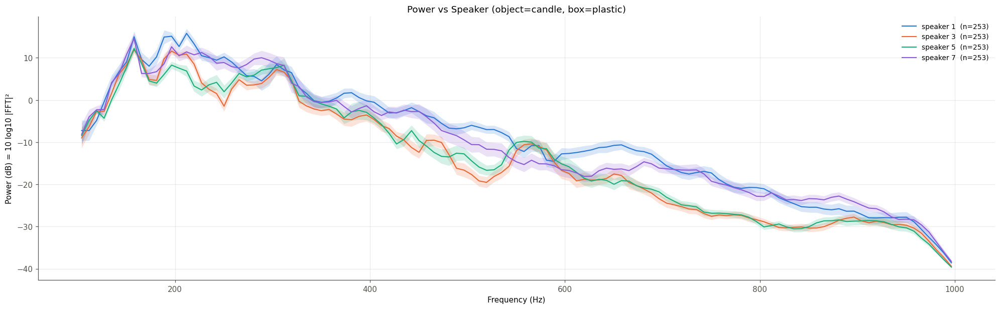

In [4]:
P.plot_avg_fft(RUN, 'speaker', 'plastic', 'candle');

**Reading:**
- The speakers drive the box very differently: up to 5–10 dB apart. Speakers 1 and 7 are 5–10 dB louder than 3 and 5 above ~600 Hz.
- The bands are narrow (≈ 1 dB): within one speaker, where the candle sits changes the *average* spectrum only a little.
- This is why spectra are only ever compared within one speaker.

**Candle, speaker 1, one line per box:**

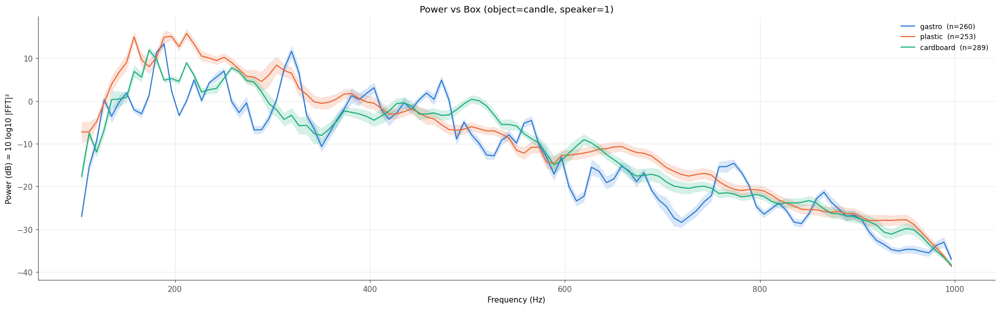

In [5]:
P.plot_avg_fft(RUN, 'box', objects='candle', speakers=1);

**Reading:**
- Each box has its own fingerprint. Gastro is jagged, with sharp resonance peaks (swings of ~20 dB over a few Hz); plastic and cardboard are smooth.
- The overall slope is the same in all three (≈ +10 dB at 150–200 Hz down to −38 dB at 1000 Hz). The slope comes from what all three share (speaker, chirp, lasers), not from the box.

**Plastic box, speaker 1, one line per object:**

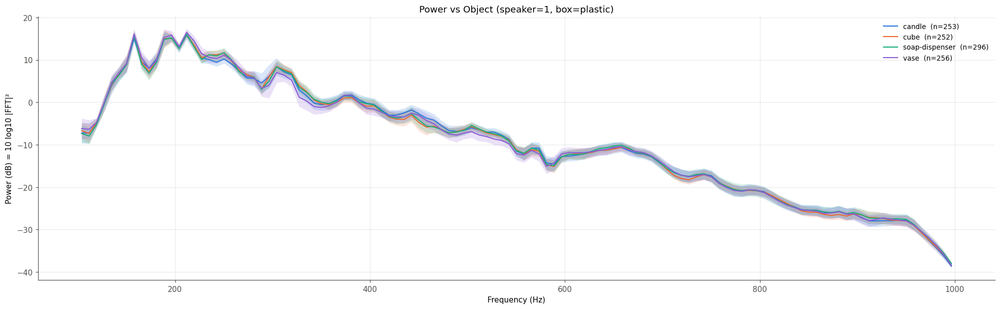

In [6]:
P.plot_avg_fft(RUN, 'object', 'plastic', None, speakers=1);

**Reading:**
- The four objects' average spectra are almost identical: within ~1–2 dB. The vase is about 2 dB lower near 300–350 Hz and 500 Hz.
- Averaged over lasers and positions, the spectrum barely says *which* object is in the box. Whatever the model uses is in how the spectrum is spread over the lasers and how it changes with position (0.3 onward).

**Plastic box, candle, speaker 1, one line per laser row, then per laser column:**

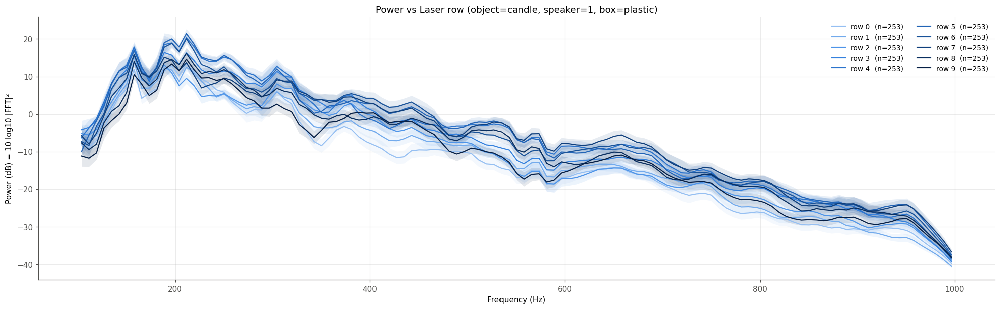

In [7]:
P.plot_avg_fft(RUN, 'laser_row', 'plastic', 'candle', speakers=1);

**Reading:**
- Laser rows differ by up to ~10 dB. The middle rows (4–7) are loudest; the top rows (0–1) and row 9 are quietest.
- This matches the mode shapes (0.8): the wall vibrates in bands along its rows.

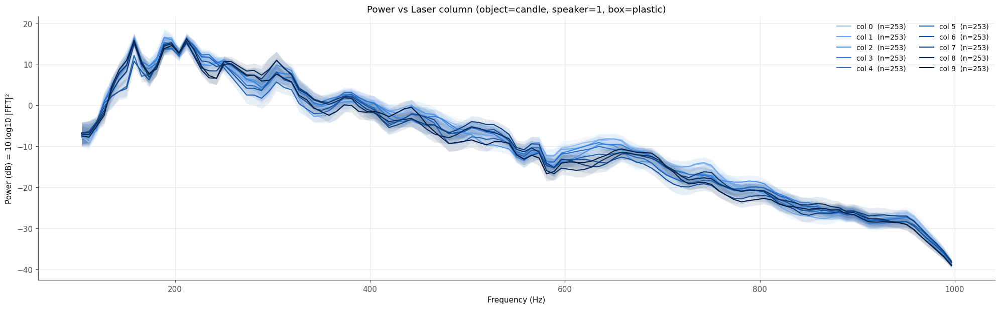

In [8]:
P.plot_avg_fft(RUN, 'laser_col', 'plastic', 'candle', speakers=1);

**Reading:**
- Columns differ much less than rows (~3 dB, mostly near 250–300 Hz and 600–700 Hz).
- The vibration changes much more from row to row than from column to column. The same holds for the strongest mode shapes in 0.8.

**Plastic box, candle, speaker 1, one line per position row of the candle on the floor, then per position column:**

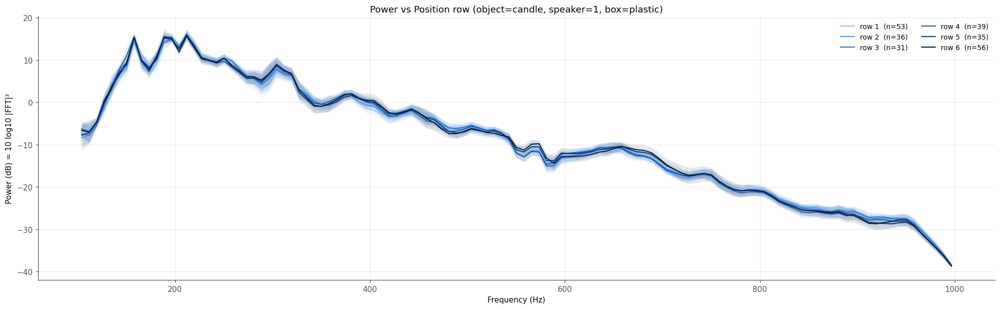

In [9]:
P.plot_avg_fft(RUN, 'pos_row', 'plastic', 'candle', speakers=1);

**Reading:**
- Where the candle sits along the floor's rows barely changes the average power: the strips lie within ~1–2 dB of each other, with the biggest gaps near 550–580 Hz. The strips next to either wall (rows 0 and 7) have fewer than 5 captures and are dropped.

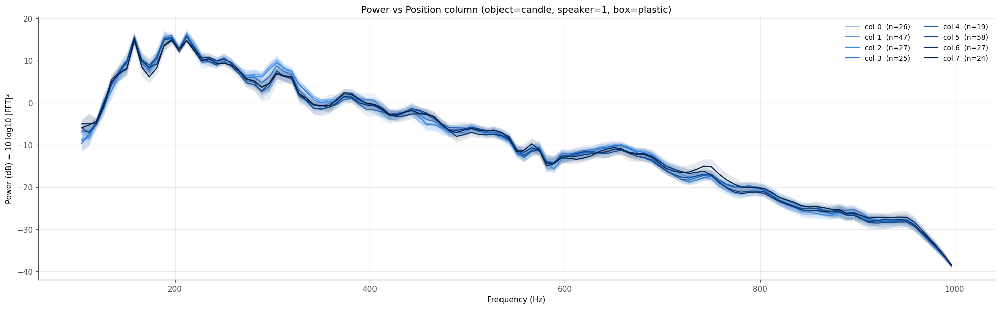

In [10]:
P.plot_avg_fft(RUN, 'pos_col', 'plastic', 'candle', speakers=1);

**Reading:**
- The same for columns: within ~1–2 dB, the largest gaps near 300 Hz and 750 Hz.
- Compare this with the laser rows (~10 dB). Moving the candle hardly changes the *total* power; it changes *how the power is spread over the lasers*. That is why 0.3–0.4 compare full per-laser spectra, not averages.

### 0.3 Spectral distance over the floor
`D_spec` from one reference position to every other position of the same object and speaker. Two figures. First: one dot per position on the box's whole overhead photo (not cropped further); the star is the reference. Second: the same binned over the floor.
- **Colour** (light = close to the reference, dark = far) uses 9 *quantile* steps: each colour holds the same share of the values, so small differences near the reference become visible.
- This is not a distortion: the colourbar labels each step with its real dB value, and the numbers in the bins are real. An exponential or log scale would instead exaggerate some gaps and hide others. `position=` takes a position id; the default is the position closest to the middle of the floor. With several objects, each object's reference is its own position closest to that spot; the per-position value is the mean over speakers, and a bin is the mean over objects. The title gives the repeat noise to read it against. `P.plot_spec_map(RUN, box, objects, speakers, position)`.

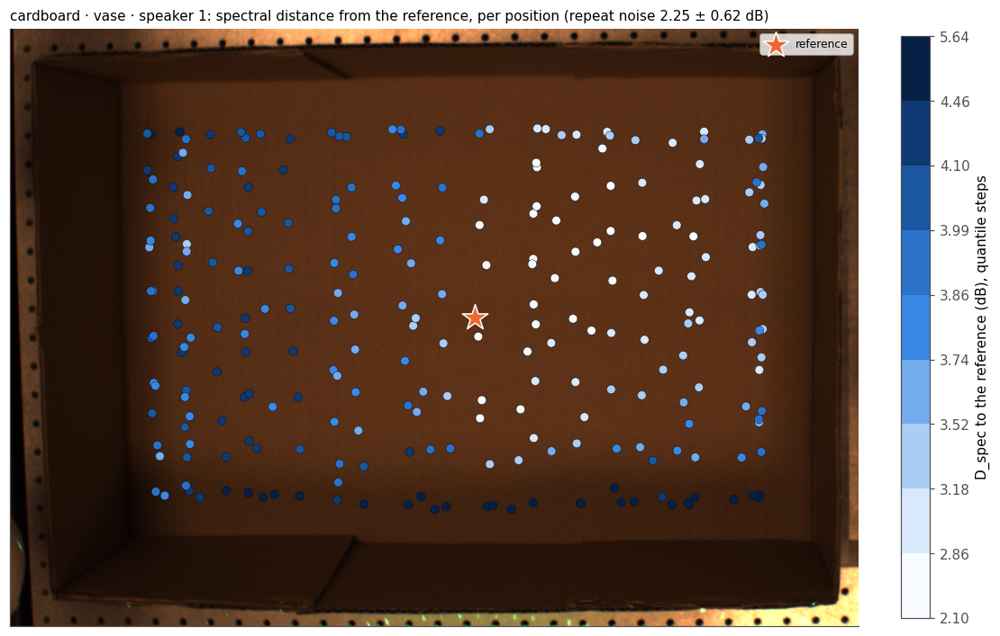

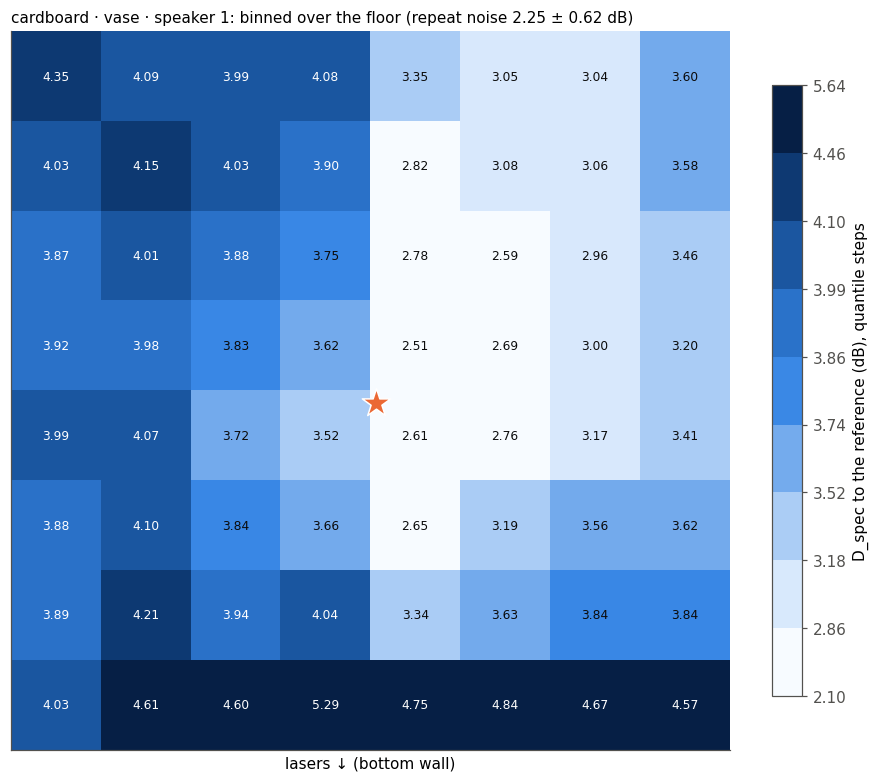

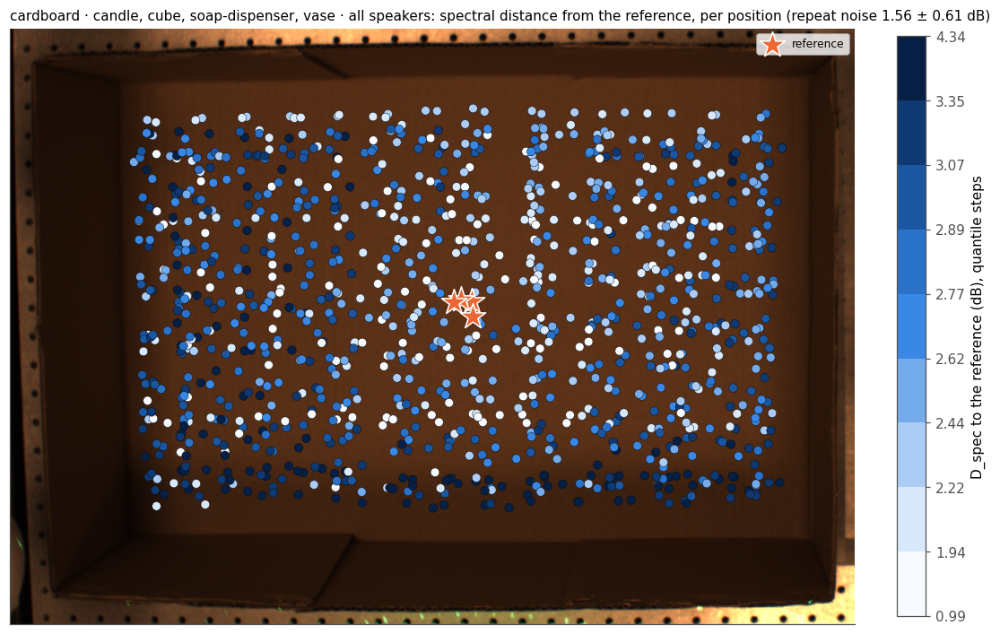

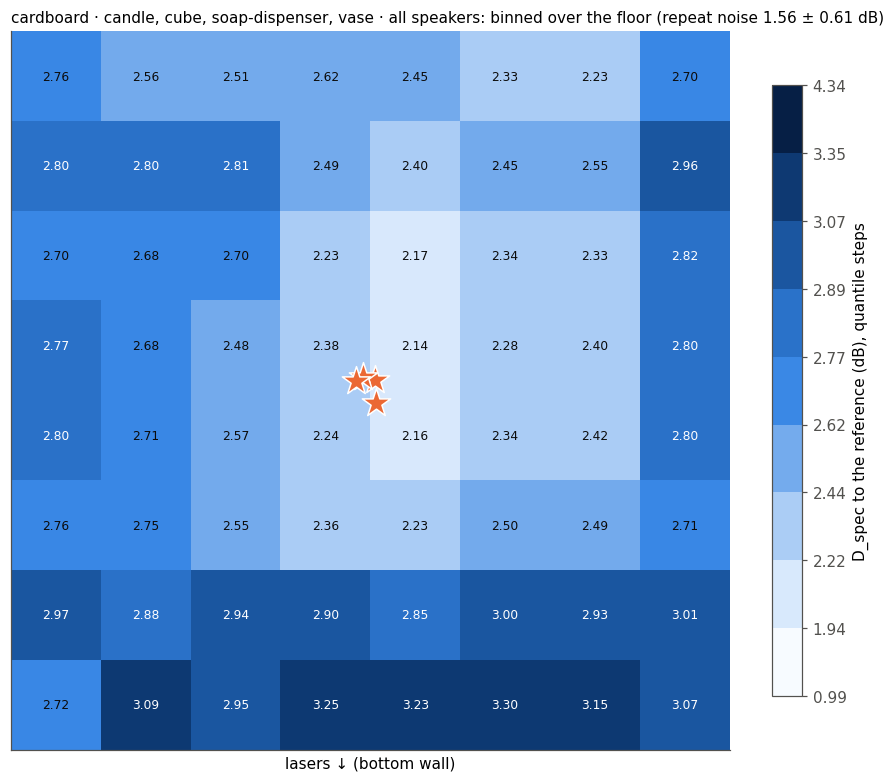

In [11]:
P.plot_spec_map(RUN, 'cardboard', 'vase', speakers=1);
P.plot_spec_map(RUN, 'cardboard');

**Reading:**
- **Vase, speaker 1:** distance grows with position, but not as a ring around the reference. Positions in the reference's *column* (the same distance from the left and right walls) stay close (2.5–2.8 dB) all the way to the back wall. The left half of the box is the farthest (≈ 4 dB), and so is the row next to the laser wall (4.6–5.3 dB).
- **All four objects, all speakers:** the same picture, smoother. 2.1–2.4 dB near the middle, ~2.8 at the side walls, ~3.0–3.3 along the laser wall.
- Even the nearest bins sit well above the repeat noise (2.25 for speaker 1 alone, 1.56 pooled). Two captures at almost the same spot, recorded minutes apart, differ more than back-to-back repeats (drift, 0.5).
- The laser-wall row is the most distinct region: an object right next to the lasers changes what they see the most. This matches nb95 (edges are louder, with a coherent low-frequency shift).

### 0.4 Spectral change vs distance moved
nb99's `S(Δ)` for every box. Take every pair of captures of one (object, speaker), bin the pairs by `D_pos` (0.04 of the box per bin), and average their `D_spec`. Bins with < 5 pairs are dropped. Line = mean over groups, band = ± pooled std over pairs, dashed = repeat noise.
- `move = mean D_spec(D_pos > 0.25) − mean D_spec(0 < D_pos < 0.05)`: the rise of the curve, i.e. the position signal.
- `move / noise`: that rise in units of repeat noise (in the legend, mean ± std over groups). Below 1, moving the object across the box changes the spectrum less than recording twice.

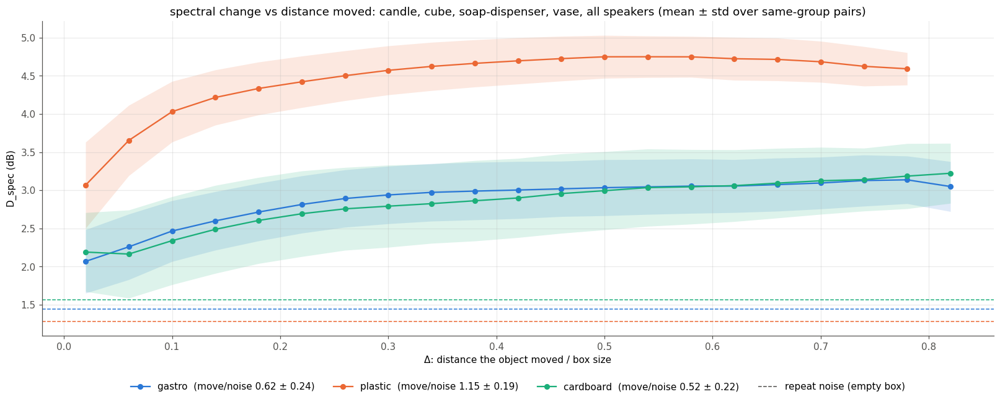

In [12]:
P.plot_spec_vs_pos(RUN);

**Reading:**
- Plastic's spectrum responds most to position: it rises from 3.1 to 4.5 dB within the first 30% of the box, and move / noise = 1.15 ± 0.19.
- Gastro (0.62 ± 0.24) and cardboard (0.52 ± 0.22) rise slowly and about equally. Moving an object across the whole box changes their spectrum by about half a repeat noise more than moving it a little. Over these four objects both are higher than nb99 found for the cube alone (0.35 / 0.34): the cube is the hardest object.
- Even the closest pairs (Δ < 0.04) sit 0.6–1.8 dB above the noise lines: the session drift (0.5).
- Plastic is also the loudest-changing box *overall* (≈ 4.5 dB at large Δ vs ≈ 3 dB), so the object's presence and its position both show up more strongly there.

### 0.5 The empty box over the session
Is the setup the same at the end of a session as at the start? Each line is one empty-box layout (light = earliest, labelled with its start time), showing `L(f)` per speaker averaged over its 3–4 back-to-back captures, then over speakers. Band = ± std over those captures. The table compares the two kinds of change, within one speaker, mean ± std over pairs:
- **repeat noise**: back-to-back captures of the same layout;
- **drift**: captures of different layouts, recorded hours apart.

,gastro,plastic,cardboard
layouts,4,5,6
captures,36,60,76
session span (h),6.5,5.3,4.9
repeat noise (dB),1.45 ± 0.37,1.28 ± 0.30,1.56 ± 0.61
drift between layouts (dB),2.01 ± 0.29,2.60 ± 0.51,2.74 ± 0.60
drift / noise,1.39,2.03,1.75


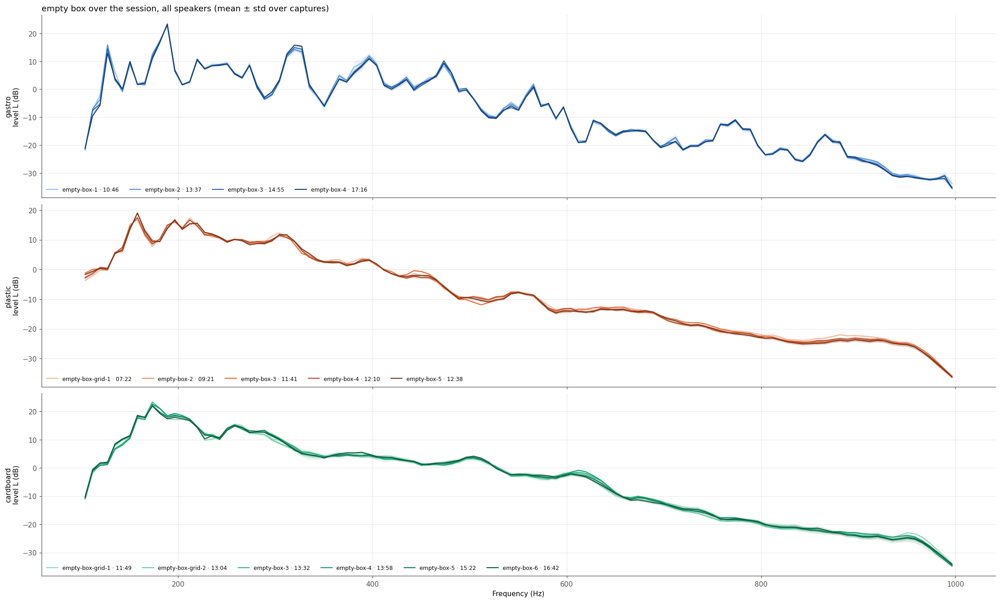

In [13]:
P.plot_empty(RUN);
P.table_empty(RUN)

**Reading:**
- The empty box is stable to within about a dB over 5–6.5 hours in every box. The layout lines lie on top of each other, and the shape of the spectrum (every peak and dip) is unchanged.
- But drift is real: captures hours apart differ by 2.0 / 2.6 / 2.7 dB against a repeat noise of 1.45 / 1.28 / 1.56 dB (gastro / plastic / cardboard), so drift / noise = 1.4 / 2.0 / 1.75. Plastic and cardboard drift the most relative to their noise.
- How it compares with what an object does (0.4): in gastro and plastic, drift (2.0 and 2.6 dB) stays well below the change from moving an object across the box (≈ 3.0 and 4.6 dB). In cardboard the two are close (2.7 vs ≈ 3.1 dB), so drift is a large part of what tells cardboard captures apart, and a model can mistake recording time for position there.
- Drift is also why no two captures at the same spot ever look as alike as back-to-back repeats.

### 0.6 Envelope and time to noise
How fast the box goes quiet after the speaker's impulse (nb99 section 5). Per capture, from the raw shifts (band-passed, no window):
- impulse response `h = irfft(X / C)`, where `C` is the spectrum of the chirp that was played;
- envelope `E(t) = 10 log10 smooth_10ms mean_{l,c} h²`, in dB re its peak;
- noise floor = the same quantity for the silent start of the capture (before the chirp), as energy per sample;
- **time to noise** = the first `t` with `E ≤ floor + 1 dB` (searched up to 0.75 s).

Uses **every empty-box capture** (36 / 60 / 76 for gastro / plastic / cardboard). `P.plot_envelope(RUN, objects, speakers)` takes any split names (default `'empty-box'`) and speakers (default all). First figure: the 100–1000 Hz envelope, mean ± pooled std over captures, with the noise floor dashed and the mean time to noise dotted. Second figure: time to noise per band, octaves in increasing frequency and then the whole band; the % is the share of captures that reach the floor within 0.75 s.

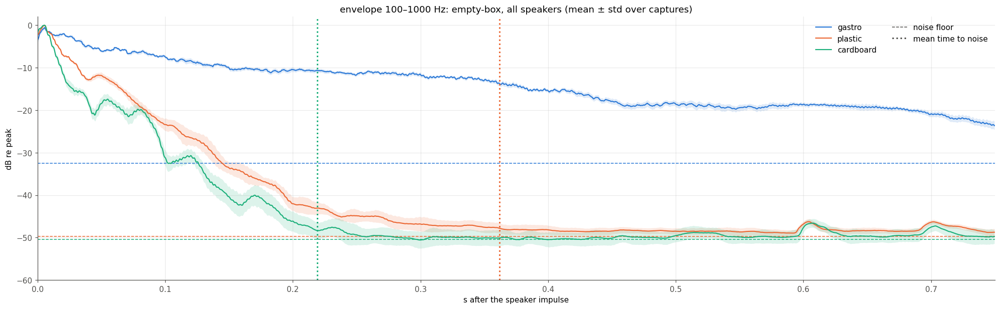

In [14]:
P.plot_envelope(RUN);

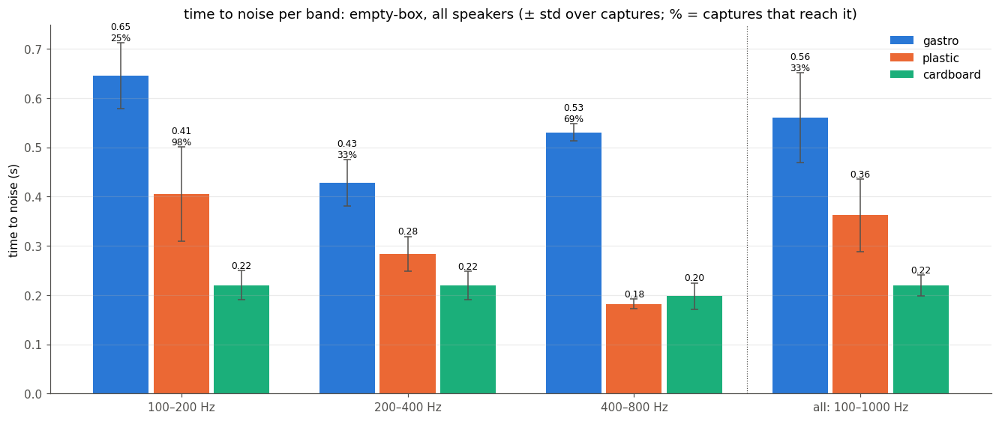

In [15]:
P.plot_time_to_noise(RUN);

**Reading:**
- Cardboard goes quiet first: 0.22 s over 100–1000 Hz, and 0.20–0.22 s in every octave.
- Plastic takes 0.36 s. It rings long at low frequency (0.41 s, 100–200 Hz) and dies fast above 400 Hz (0.18 s, as fast as cardboard there).
- Gastro rings for seconds. Only a third of its captures reach the noise floor within 0.75 s.
  - Its floor (−32.5 dB) is inflated: the 'silent' start of a capture still holds the previous chirp's ringing (nb99). So its times to noise are lower bounds at best.
- The bands are tight (± 0.01–0.1 s), and the same numbers came out with the four objects in the box: damping belongs to the box, not to what's in it.
- The bumps at 0.6 and 0.7 s are harmonic-distortion responses of the log sweep, not ringing.

### 0.7 Cumulative energy of the spatial patterns
How many distinct spatial patterns (mode shapes) does the box have? Per (object, speaker), every capture's `X` becomes a `1170 × 200` matrix: row `f` is the 100 lasers × 2 axes at `f`, scaled to unit length, so only its *shape* counts. All captures of the group are stacked, then:
- `X = U S Vᴴ`: the columns of `V` are the spatial patterns, and `s_k²` is pattern `k`'s energy;
- cumulative energy `Σ_{j≤k} s_j² / Σ s²`;
- `eff_rank = (Σ s²)² / Σ s⁴` (= r if the energy is spread evenly over r patterns);
- `n90` = the number of patterns that hold 90% of the energy.

One curve per group, and the band is ± std *between* groups (speakers and objects). Dots mark every k. The eigenvalues are cached per group.

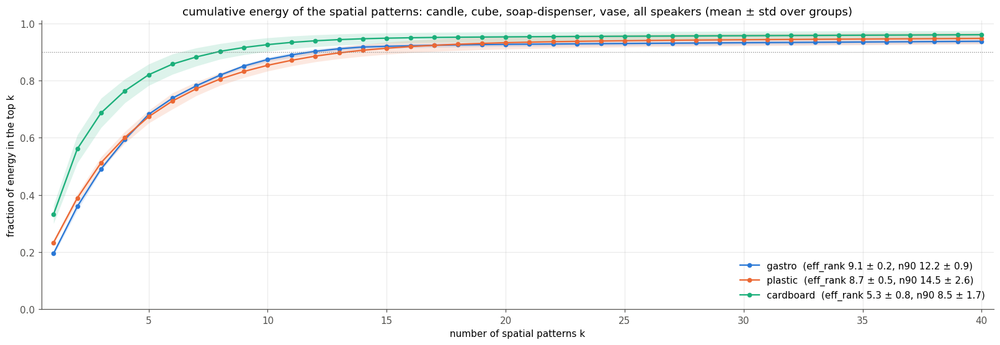

In [16]:
P.plot_cumulative_energy(RUN);

**Reading:**
- Cardboard has far fewer spatial patterns: eff_rank 5.3 ± 0.8 vs 9.1 (gastro) and 8.7 (plastic), and n90 = 8.5 vs 12.2 and 14.5. Its first pattern alone holds 33% of the energy (gastro 20%, plastic 23%).
- These are nb99's cube + empty numbers (9.2 / 8.4 / 5.4) to within a few tenths. The four objects don't add patterns: the pattern count belongs to the box.
- Gastro and plastic are close up to k ≈ 15. After that plastic keeps a longer tail of weak patterns (its shape drifts smoothly with frequency).
- No curve reaches 1. The last 4–7% of the energy is spread thinly over the remaining ~160 directions, which is the noise floor of the shapes.

### 0.8 The top 3 mode shapes
What do the patterns of 0.7 look like? No peak picking is involved: the patterns come from all frequencies at once (an SVD). The stacked matrix `X` has one row per (capture, frequency) and one column per laser channel (100 lasers × x/y shift):
- `X = U S Vᴴ`;
- **columns of V** = the spatial patterns: one complex weight per laser and axis. This is the mode shape, and it is what is drawn;
- **columns of U** = how strongly each row (one frequency of one capture) uses that pattern, i.e. where in frequency and in which captures it is active;
- `s_k²` = pattern k's energy; its share `s_k² / Σ s²` is in each title.

Shapes are computed for one speaker (default 1), with all four objects stacked. A shape's sign and global phase are arbitrary, and shapes from different speakers or objects can't be averaged. So each one is rotated to be as real as possible (phase `½ arg Σ v²`), and its largest entry is made positive.
- **Colour** = `Re v` on the dominant axis (scaled to max 1). Nodal lines are where it changes sign.
- **Arrows** = `(Re v_x, Re v_y)`, the in-plane shift direction of each laser spot.
- The second energy number in each title is the mean ± std over every (object, speaker) group.
- Grid: laser `l` at (row `l // 10`, column `l % 10`) in the camera's laser order. Not yet checked against the floor's orientation.

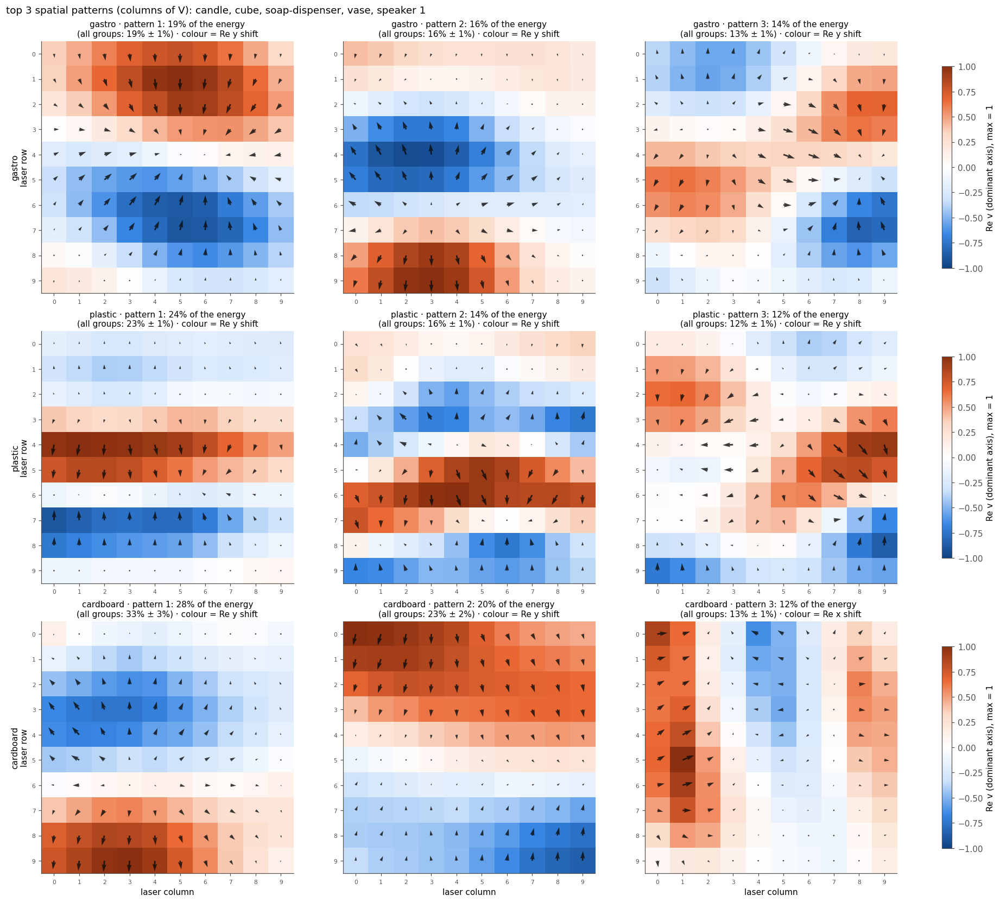

In [17]:
P.plot_mode_shapes(RUN, speaker=1);

**Reading:**
- The strongest patterns are **bands across laser rows**, mostly in the y shift: standing waves along the wall's row direction.
  - gastro pattern 1 (19%): rows 1–2 against rows 6–7, one nodal line.
  - plastic pattern 1 (24%): rows 4–5 against rows 7–8.
  - cardboard pattern 1 (28%; 33 ± 3% over groups): rows 2–4 against rows 8–9, strongest on the left half.
- Pattern 2 adds a nodal line in every box: three bands in gastro and plastic, top half against bottom half in cardboard.
- Pattern 3 is where the boxes differ. In gastro and plastic it is a 2-D, checkerboard-like shape (rows *and* columns). In cardboard it is the only one in the **x** shift, as column bands (0–2 against 4–5).
- The energy shares are very stable across groups (± 1–3%): the same shapes come back for every object and speaker. They are the box's shapes, consistent with 0.7.
- Cardboard puts the most energy in its first two patterns (48% here, against 35% gastro and 38% plastic). That is why its cumulative curve rises fastest and its eff_rank is lowest.

### 0.9 What changes when an object moves: mode frequency, amplitude or shape?
Every mode has a **frequency**, an **amplitude**, and a **shape**. *Shape* means the mode shape: how the vibration is spread over the 100 lasers (the 200 x/y shifts at one frequency, `u(f)`, scaled to unit length). It is *not* the shape of the spectrum curve.

For two captures a and b (same speaker), in 9 windows of ~100 Hz:
1. **Align → frequency.** Slide b's level curve `l_b(f)` left or right, by up to 10 Hz, until it best matches `l_a(f)` (highest correlation). The slide `τ` is the frequency shift: if the object detunes the modes, the peaks move, and `τ ≠ 0`.
2. **Amplitude** = the level difference left after the slide: `rms_f (l_a(f) − l_b(f + τ))`, in dB.
3. **Shape** = how different the mode shapes are at matching frequencies: `mean_f (1 − MAC)`, with `MAC = |u_a(f) · u_b(f + τ)*|²`. 0 = same shape, 1 = unrelated.

Aligning first means a pure frequency shift is counted once, as frequency, and not again as amplitude or shape.

**The plot** (the cube, in every box):
- **Top**, one panel per part. x = frequency window; y = how much that part changed.
  - Solid = two captures with the cube far apart (> 25% of the box).
  - Dashed = two back-to-back recordings of the empty box (repeat noise).
  - Solid above dashed = moving the cube changes that part.
- **Bottom:** for each part, the share of cube moves that change it more than 95% of the repeat recordings do. 0.05 = no effect (chance), 1 = every move changes it.

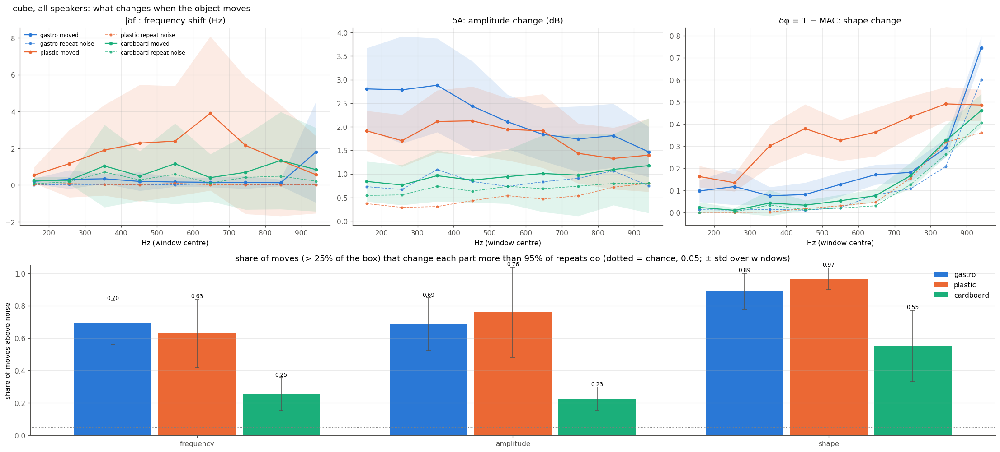

In [18]:
P.plot_mode_changes(RUN, 'cube');

**Reading:**
- **Shape changes most reliably:** 89% / 97% / 55% of moves (gastro / plastic / cardboard).
- **Frequency:**
  - gastro's sharp modes shift by ~0.4 Hz (repeats: 0.03 Hz), in 70% of moves;
  - plastic shifts by ~1.8 Hz, but its peaks are broad, so the estimate is looser;
  - in cardboard only 25% of moves stand out, because its repeats already jitter by 0.3 Hz.
- **Amplitude:** 69% / 76% / 23% of moves.
- So moving the cube changes all three parts, the mode shape most. Cardboard changes least in every part.
- Above ~800 Hz even repeats differ in shape (the dashed lines rise): noise dominates there.

### 0.10 Do the four objects change the box differently?
If a *different* object sits on the same spot, does the box respond differently, or does only the position matter?
- Take two captures whose objects sit at the same spot (centres < 5% of the box apart), with the same speaker.
- **Diagonal** cell = the same object both times (e.g. cube, then cube again at that spot). **Off-diagonal** = two different objects (e.g. cube vs vase).
- **Fair timing.** Each object was recorded in its own 1–2 h session, so two different objects are always ≥ 30 min apart, and the box drifts over time (0.5). So *every* cell uses only pairs recorded 30–120 min apart: the same drift everywhere. The same-object cells exist because each object's grids revisit spots.
- Two measures: the spectral distance (whole spectrum, dB) and the mode-shape change `1 − MAC` (0.9). Light = small, dark = big. Each cell gives mean ± std over pairs, and n = number of pairs.
- Each panel title gives the mean of the same-object cells, the mean of the different-object cells, and the empty box against itself at the same gap (drift alone).

Diagonal ≈ off-diagonal → the box can't tell those objects apart, only where they are. Off-diagonal bigger → the objects change the box differently.

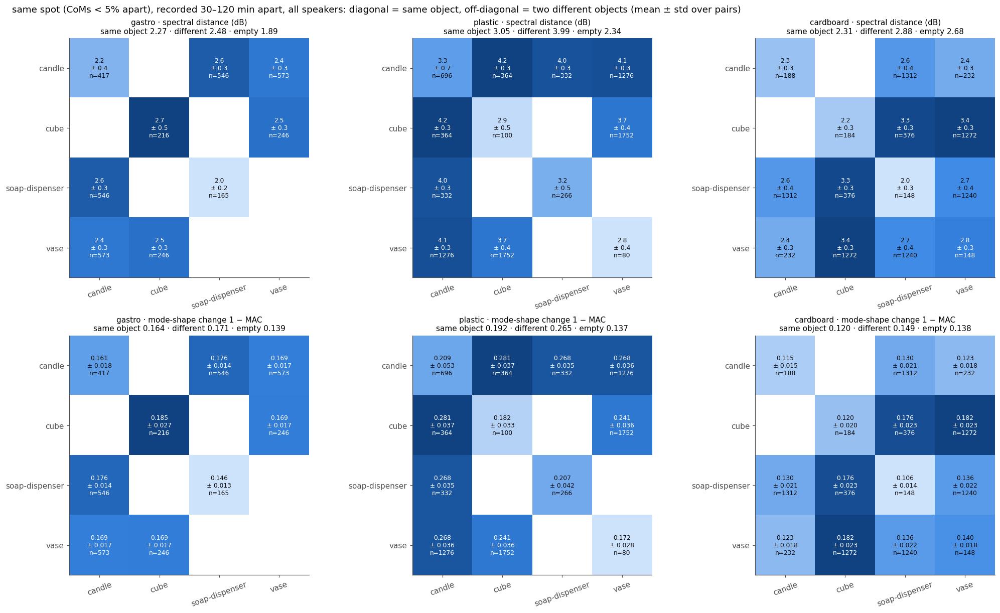

In [19]:
P.plot_objects(RUN);

**Reading:**
- **Plastic: yes, the objects change the box differently.** Two different objects at the same spot differ by 3.7–4.2 dB (mode shape 0.24–0.28), against 2.8–3.3 dB (0.17–0.21) for the same object back at that spot. Both are well above the empty box's drift at the same gap (2.34 dB, 0.137).
- **Cardboard: only the cube stands apart.** Cube vs any other object: 3.3–3.4 dB (shape 0.18). Candle, soap dispenser and vase look alike: 2.4–2.7 dB between them, about the same as one object against itself (2.0–2.8). Caveat: the cube was the first session of the day, when nb99 found the setup still drifting.
- **Gastro: small differences.** Different objects 2.48 dB vs same object 2.27 (shape 0.171 vs 0.164). Several cells are blank: the gastro sessions are far apart (cube vs candle ≈ 4 h), and its vase grid never revisits a spot after 30 min.
- So the answer depends on the box. In plastic each object leaves its own fingerprint; in gastro and (apart from the cube) cardboard, the box mostly tells *where* the mass is, not *what* it is.
- The gap is matched (30–120 min), not identical. A perfectly fair test would record the objects interleaved at the same spots.

### 0.11 The box's own resonances
Which resonances belong to the box, there no matter where the object is? Per (object, speaker) and per FFT bin (0.77 Hz):
- **peaks** are picked as in viz2: on `σ(f)` = the std of `|X|` across the 200 laser channels (a real mode is where the lasers *disagree*), smoothed over 5 Hz, with a prominence ≥ 4 × the robust (MAD) noise of its residual from a 25 Hz baseline, and ≥ 5 Hz apart;
- **occurrence** = the share of captures with such a peak within ±2.3 Hz;
- **σ_pos** = std of `l(f)` over the captures (i.e. over positions);
- **σ_rep** = the same std over back-to-back empty captures (repeat noise).

These are averaged over groups. A **box resonance** = a peak of the group-mean `σ(f)` that occurs in ≥ 80% of captures. Its **jitter** = the std of the nearest peak's frequency over captures. Top of each pair: mean level ± σ_pos, with the box resonances as dots. Bottom: σ_pos (solid) vs σ_rep (dashed), with the occurrence in grey on the right axis.

,resonances,jitter_hz,sigma_pos,sigma_rep
box,,,,
cardboard,4,1.07,0.74,0.34
gastro,12,0.61,2.20,0.71
plastic,1,1.00,1.31,0.21


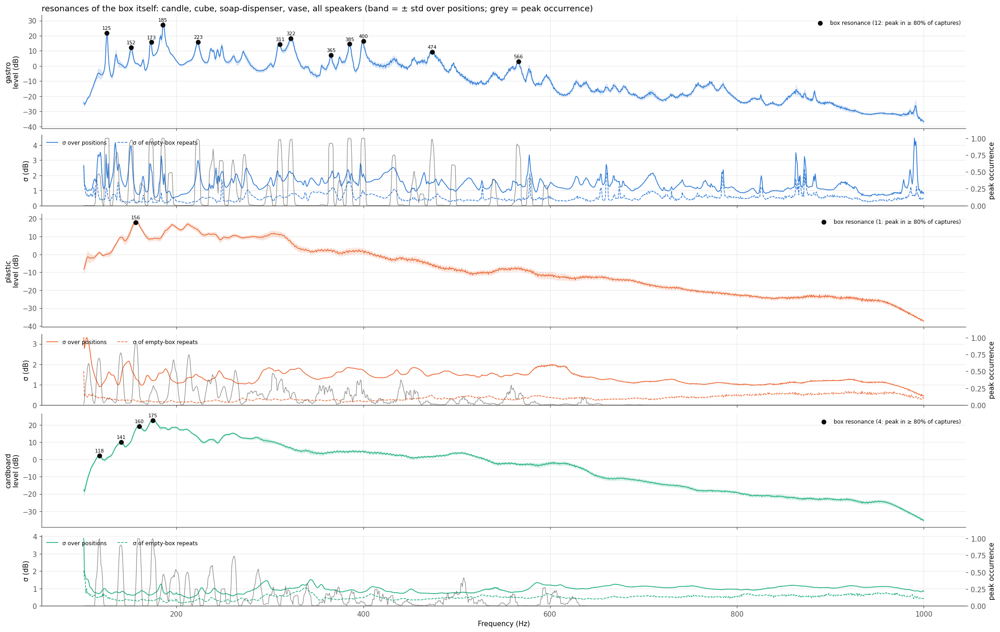

In [20]:
curves, res = P.box_resonances(RUN)
P.plot_box_resonances(RUN);
res.groupby('box').agg(resonances=('f0', 'size'), jitter_hz=('jitter_hz', 'mean'), sigma_pos=('sigma_pos', 'mean'), sigma_rep=('sigma_rep', 'mean')).round(2)

In [21]:
res

,box,f0,level,occurrence,jitter_hz,sigma_pos,sigma_rep
0,gastro,125.38,21.76,1.00,0.28,2.27,1.16
1,gastro,151.54,12.29,0.97,0.63,3.95,0.37
2,gastro,173.08,15.70,0.99,0.55,2.36,0.56
3,gastro,185.38,27.11,1.00,0.67,1.85,0.32
4,gastro,223.08,15.81,0.98,0.55,2.99,0.32
5,gastro,310.77,14.31,0.98,0.80,2.01,0.66
6,gastro,322.31,18.26,0.98,0.77,2.19,0.76
7,gastro,365.38,7.30,0.92,0.30,2.02,1.06
8,gastro,385.38,14.50,1.00,0.47,1.85,1.58
9,gastro,400.00,16.56,1.00,0.47,2.09,0.87


**Reading:**
- **Gastro has 12 box resonances** (125, 152, 173, 185, 223, 311, 322, 365, 385, 400, 474 and 566 Hz), each present in 89–100% of captures.
  - They barely move: the jitter is 0.3–1.2 Hz, against peaks spaced 10–40 Hz apart.
  - Their *level* changes with position: σ_pos ≈ 2.2 dB on average, against σ_rep ≈ 0.7 dB for repeats.
  - So the object changes how strongly each fixed mode is driven more than where it sits in frequency.
- **Cardboard has 4, all low** (118, 141, 160, 175 Hz). **Plastic has 1** (156 Hz). Above ~200 Hz neither has a peak that comes back in most captures: their spectra are a smooth slope with broad humps, and where a capture does have a peak, it moves between positions (occurrence ≲ 0.5).
- σ_pos is above σ_rep at almost every frequency in every box: position changes the level everywhere, not only at the resonances. In gastro, σ_pos peaks *at* the resonances; in plastic and cardboard it is spread across the band.
- Together with 0.9: in the stiff steel box, the object re-weights and slightly shifts a fixed set of sharp modes. In the damped boxes there are few stable modes to track, and the position information is in the mode shape.

## 1 Load

In [ ]:
df = P.load(RUN, EPOCH, THR)
knn = P.knn(RUN, df)   # first run builds the input features (runs/_paper_cache, ~2 min)
print(f"{RUN} @ epoch {df.attrs['epoch']}:", df.set.value_counts().to_dict())

s8-mag-nopose-imom-r2-500ep @ epoch 500: {'train': 10676, 'eval': 4554}


## 2 Table 1: in distribution

In [ ]:
t = P.table_id({'kNN': knn, 'VibroFormer': df}, 'iou')
P.to_latex(t, OUT / 'table1_iou.tex', caption='In distribution: IoU')
P.style(t)

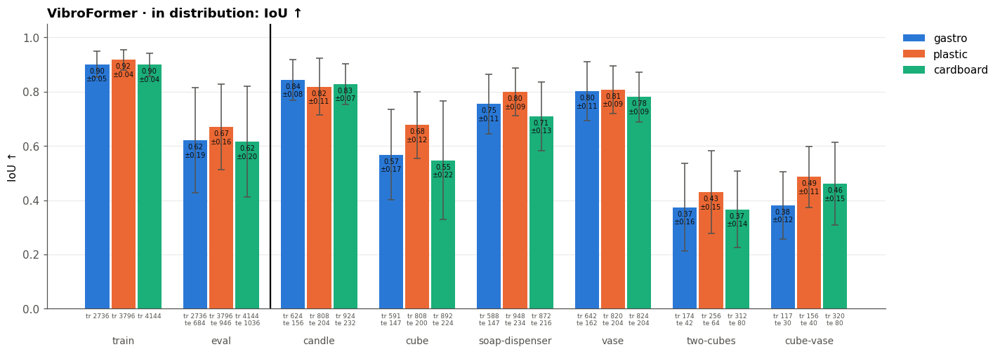

In [ ]:
P.plot_table_id(df, 'iou');

In [ ]:
t = P.table_id({'kNN': knn, 'VibroFormer': df}, 'miss')
P.to_latex(t, OUT / 'table1_miss.tex', caption='In distribution: miss rate')
P.style(t)

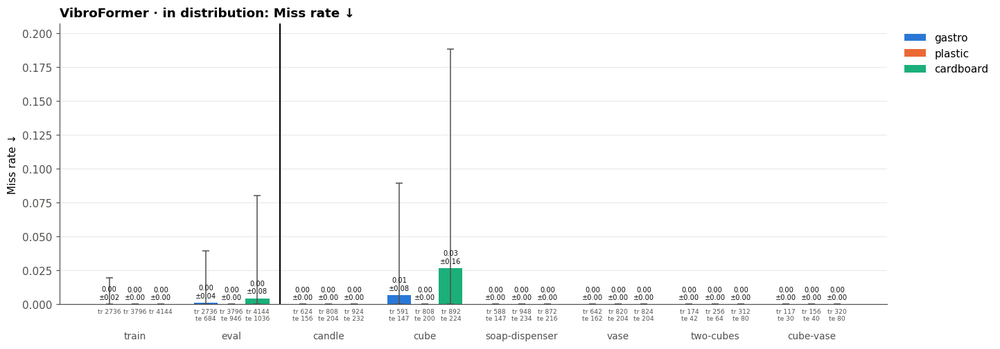

In [ ]:
P.plot_table_id(df, 'miss');

In [ ]:
t = P.table_id({'kNN': knn, 'VibroFormer': df}, 'com_err')
P.to_latex(t, OUT / 'table1_com_err.tex', caption='In distribution: CoM error (\\% of box)')
P.style(t)

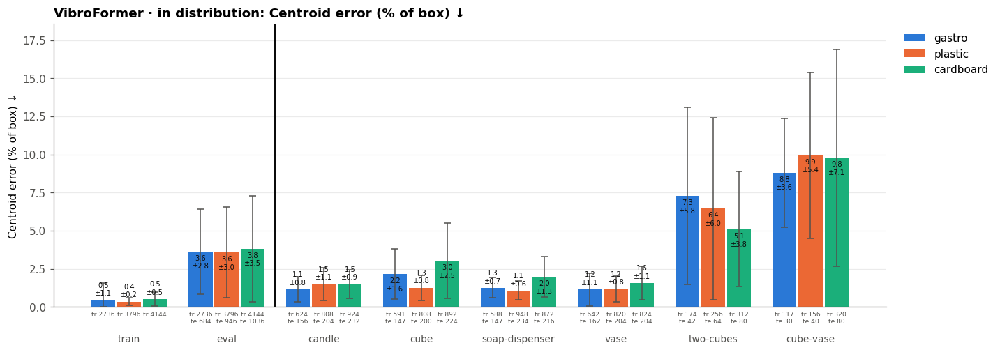

In [ ]:
P.plot_table_id(df, 'com_err');

Samples behind Table 1:

In [ ]:
P.table_n(df)

candle  cube  soap-dispenser  vase  two-cubes  cube-vase
n train gastro        624   591             588   642        174        117
        plastic       808   808             948   820        256        156
        cardboard     924   892             872   824        312        320
n test  gastro        156   147             147   162         42         30
        plastic       204   200             234   204         64         40
        cardboard     232   224             216   204         80         80

## 3 Table 2: out of distribution
Each row is shaded across the boxes. The in-distribution row is the reference.

**Unseen position (once a `--dataset paper` run exists):** the block sits in the middle of the floor, and that region is already the hardest *in distribution* (section 5: about 0.5–0.65 IoU against about 0.7 elsewhere). So don't compare its score with the overall in-distribution mean. Compare it with the same region's in-distribution score from a run that did train there, and read it along the distance curve (section 6).

In [ ]:
t = P.table_ood(df, 'iou')
P.to_latex(t, OUT / 'table2_iou.tex', axis=1, caption='Out of distribution: IoU')
P.style(t, axis=1)

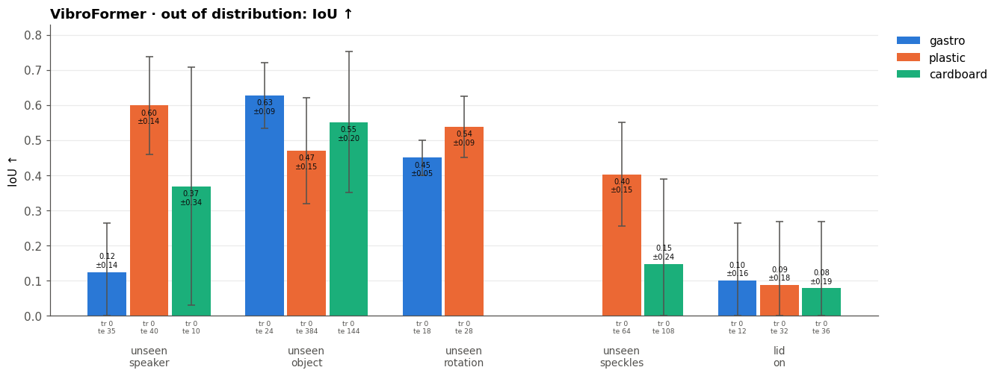

In [ ]:
P.plot_table_ood(df, 'iou');

In [ ]:
t = P.table_ood(df, 'miss')
P.to_latex(t, OUT / 'table2_miss.tex', axis=1, caption='Out of distribution: miss rate')
P.style(t, axis=1)

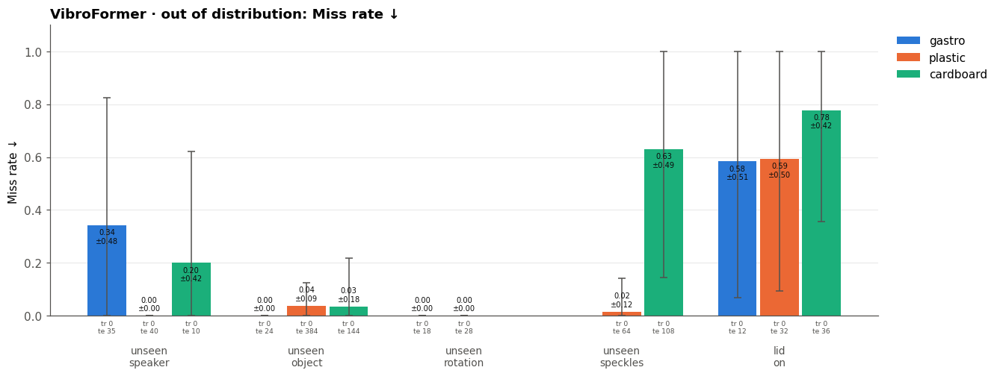

In [ ]:
P.plot_table_ood(df, 'miss');

In [ ]:
t = P.table_ood(df, 'com_err')
P.to_latex(t, OUT / 'table2_com_err.tex', axis=1, caption='Out of distribution: CoM error (\\% of box)')
P.style(t, axis=1)

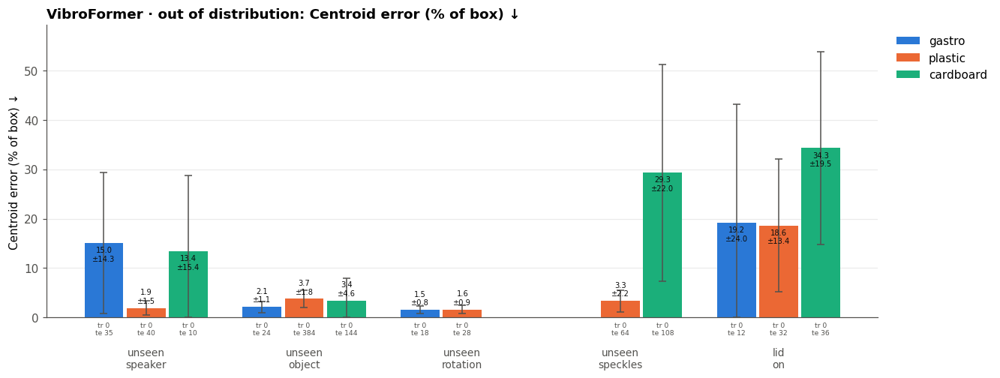

In [ ]:
P.plot_table_ood(df, 'com_err');

Samples behind Table 2 (n train of an OOD row is 0 by construction):

In [ ]:
P.table_n(df, 'category')

n train                   n test                  
                 gastro plastic cardboard gastro plastic cardboard
in distribution    2736    3796      4144    684     946      1036
unseen speaker        0       0         0     35      40        10
unseen object         0       0         0     24     384       144
unseen rotation       0       0         0     18      28         0
unseen speckles       0       0         0      0      64       108
lid on                0       0         0     12      32        36

## 3b Weight trend
The cylinders are one shape at four masses (100, 200, 500 and 1000 g), and all four are trained. So this is not a generalization test: it asks whether a lighter object gives the box less signal. Only boxes whose run trained on cylinders are shown; the current run has only cardboard. In a `--dataset paper` run, all three boxes train every weight, with 20% of positions held out.

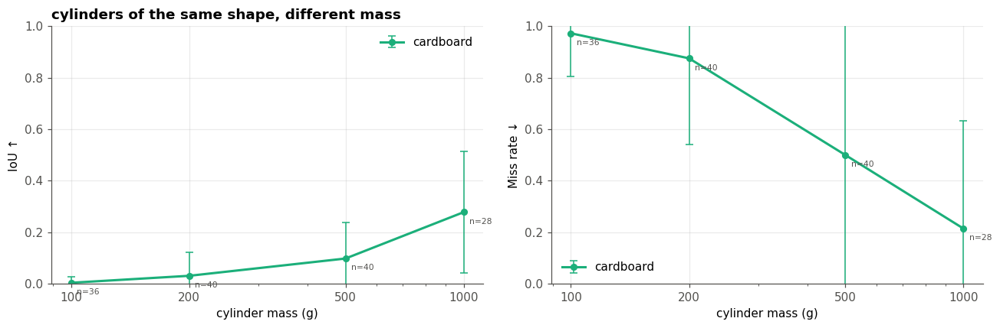

In [ ]:
P.plot_weight(df);

## 4 Table 3: aux heads
All boxes together. Box accuracy is trivial here, because the box id is an input. Objects never trained on have no class, so their row is the novelty AUROC (1 − confidence, against in distribution).

In [ ]:
t = P.table_heads(df)
P.to_latex(t, OUT / 'table3_heads.tex', color=False, caption='Auxiliary heads')
P.style(t, color=False)

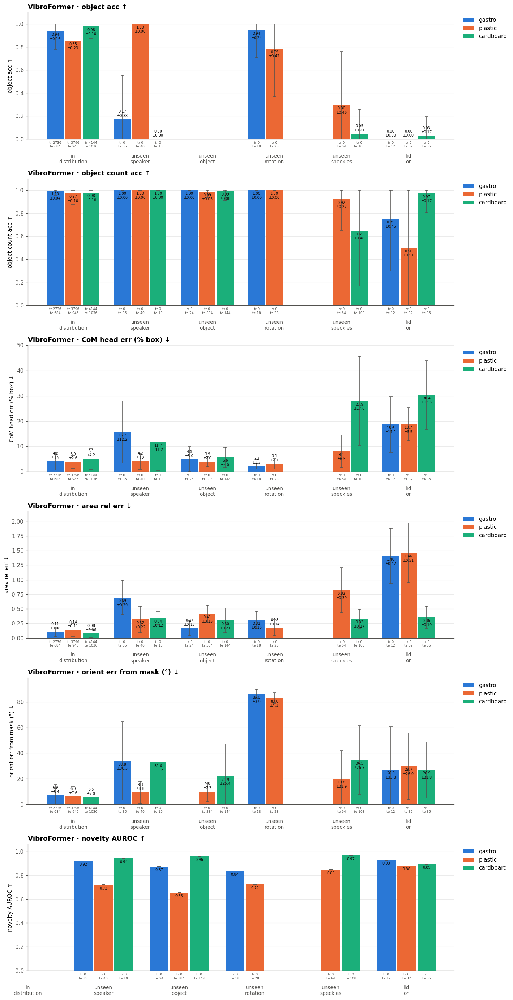

In [ ]:
P.plot_table_heads(df);

## 5 Floor error map
In-distribution IoU over the floor, binned by the true centroid. The lasers are on the bottom wall; the dashed square is the unseen-position block. A bin with fewer than 2 positions is blank: plastic has almost none next to the laser wall.

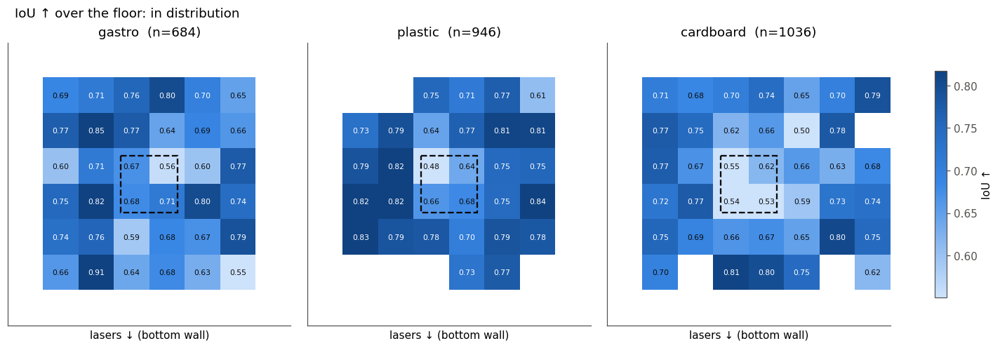

In [ ]:
P.plot_floor_error(df);

## 6 IoU vs distance to the nearest training position
Random held-out positions sit within about 3% of the box of a training position. Only the unseen-position block (paper split) reaches further out.

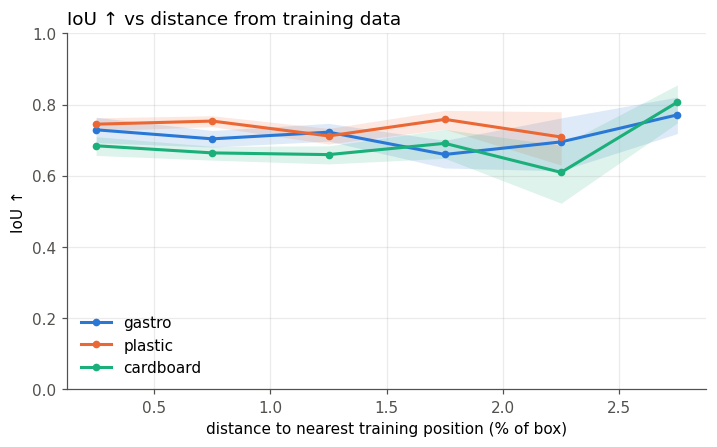

In [ ]:
P.plot_iou_vs_distance(df);

## 7 Per speaker
In-distribution performance per speaker and box, on positions all three speakers recorded (paired). Whiskers = 95% bootstrap CI over positions.

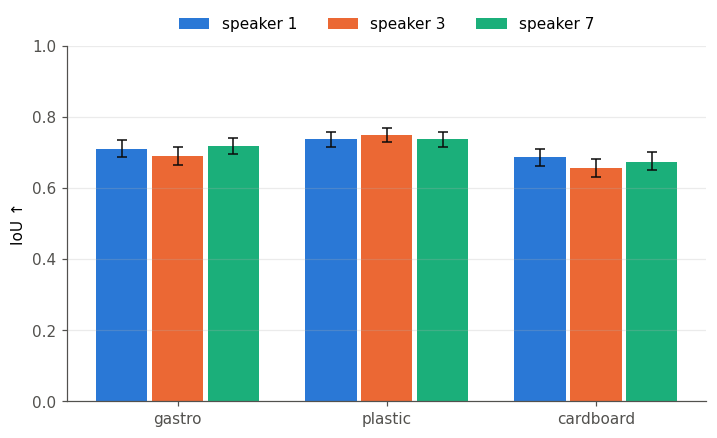

In [ ]:
P.plot_speakers(df, speakers=(1, 3, 7));

## 8 Object-head confidence
Can the model tell it doesn't know the object? The broken cup only shows up once it is held out of training (paper split).

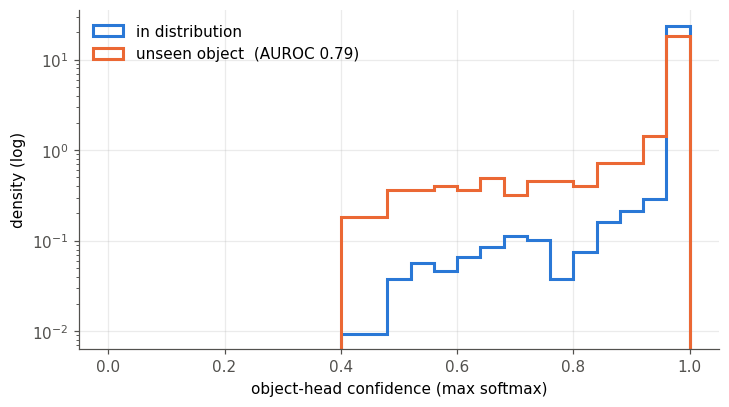

In [ ]:
P.plot_confidence(df);

## 9 Predictions per category
Speaker 1. Each row is picked at evenly spaced IoU quantiles (15–85%), not the best samples, and alternates between boxes. White = true outline, orange = prediction > THR. A lid sample's photo shows the lid; its outline is the same spot without the lid.

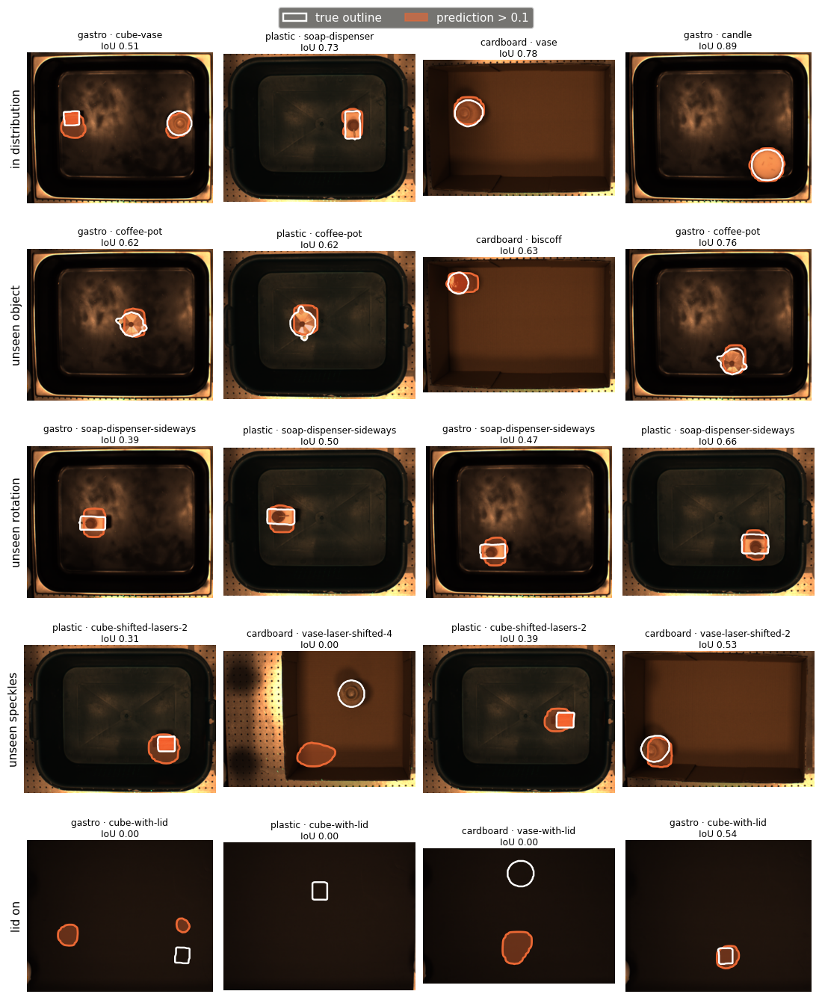

In [ ]:
fig = P.samples_figure(df, n=4)